# 2차 중간 분석: 서울 지하철 이용과 강수 기록

서울교통공사 관할 구간의 2023~2025년 승하차와 서울 ASOS(108) 일자료를 날짜 기준으로 결합한다. 이 Notebook은 자료 검증과 기초 탐색 분석만 수행한다. 강수량 빈칸은 0으로 채우지 않는다.


In [1]:
from pathlib import Path
import os, sys, subprocess, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'scripts').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
print('Project:', ROOT)
print('Python:', sys.version.split()[0])


Project: /workspaces/seoul-subway-rainfall-analysis
Python: 3.14.2


## 1. 2차 전용 자료 검증과 기초 분석 실행

원자료 적재, 후보 고유키와 공통 역 범위 확인, 시간대 변환과 날짜 결합 검증, 기초 표·그림을 실행한다.


In [2]:
run = subprocess.run([sys.executable, 'scripts/run_interim.py'], text=True,
                     encoding='utf-8', errors='replace', capture_output=True)
print(run.stdout)
if run.stderr:
    print(run.stderr)
assert run.returncode == 0, f'2차 실행 실패: {run.returncode}'


=== 2nd-stage data verification and descriptive analysis ===
Run time (KST): 2026-11-23 19:12:57
Analysis period: 2023-01-01 to 2025-12-31; daily weather records: 1096
Common station/line/code pairs: 272
Source audit: year | valid rows | fully blank rows | duplicate keys
  2023 | 199,270 | 0 | 0
  2024 | 199,410 | 0 | 0
  2025 | 199,290 | 134 | 0
Direct raw/normalized sample: Seoul Station line 1, 2023-01-01 06-07, boarding: 145 = 145
Reshape totals preserved (common and all; board and alight): True
Weather unmatched dates: 0
Hourly aggregate rows before/after join: 87680 / 87680
Join passenger totals preserved: True
Precipitation records: >=0.1 mm = 336 ; 0.0 mm = 132 ; blank = 628
Recorded 0.0 mm with rain-duration entry: 131
Unconfirmed dry candidates among blanks: 625
Output folder: /workspaces/seoul-subway-rainfall-analysis/results/interim
Stage scope: source checks, join checks and descriptive analysis only.



## 2. 출처·고유키·원본 직접 대조

고유키는 날짜·호선·역번호·승하차구분이다. 원자료의 서울역 1호선 특정 행을 정규화된 값과 직접 비교한다.


In [3]:
base = Path('results/interim/tables')
display(pd.read_csv(base / 'subway_source_audit.csv'))
display(pd.read_csv(base / 'source_direct_comparison.csv'))
display(pd.read_csv(base / 'reshape_validation.csv'))


,year,filename,encoding,raw_rows,fully_empty_rows,valid_rows,candidate_key_duplicate_rows,first_date,last_date,observed_dates,missing_dates,station_line_code_pairs,boarding_all_bands,alighting_all_bands
0,2023,subway_2023.csv,cp949,199270,0,199270,0,2023-01-01,2023-12-31,365,0,282,1547141920,1549100770
1,2024,subway_2024.csv,cp949,199410,0,199410,0,2024-01-01,2024-12-31,366,0,273,1596247904,1597499089
2,2025,subway_2025.csv,cp949,199424,134,199290,0,2025-01-01,2025-12-31,365,0,273,1620478867,1621184738


,date,line,station_code,station_name,direction,time_band,raw_count,normalized_count,equal
0,2023-01-01,1호선,150,서울역,승차,06-07,145,145,True


,population,direction,before_reshape,after_reshape,equal
0,common,승차,4760795829,4760795829,True
1,common,하차,4765057461,4765057461,True
2,all,승차,4763868691,4763868691,True
3,all,하차,4767784597,4767784597,True


## 3. 강수 표기와 날짜 결합

0.0mm 기록과 빈칸은 별도다. 빈칸 중 보조항목으로 구분한 후보는 미확인 상태다.


In [4]:
with open('results/interim/weather_merge_audit.json', encoding='utf-8') as f:
    weather_audit = json.load(f)
print(json.dumps(weather_audit, ensure_ascii=False, indent=2))
display(pd.read_csv(base / 'rain_vs_duration_crosscheck.csv'))


{
  "source_file": "asos_seoul_2023_2025.csv",
  "encoding": "cp949",
  "sha256": "3b09bfc8a78ad8295bad4ccf3a7c4f6e76a2afd2514fd08b5b5f6b2f0f587d65",
  "rows": 1096,
  "date_first": "2023-01-01",
  "date_last": "2025-12-31",
  "missing_calendar_days": 0,
  "out_of_range_days": 0,
  "rain_blank_days": 628,
  "temp_missing_days": 0,
  "dry_candidates_unconfirmed": 625,
  "rain_category_counts": {
    "blank_unresolved": 628,
    "at_least_0.1mm": 336,
    "recorded_0.0mm": 132
  },
  "rain_duration_available": true,
  "article_available": true,
  "unmatched_subway_dates": 0,
  "hourly_rows_before_merge": 87680,
  "hourly_rows_after_merge": 87680,
  "hourly_passenger_sum_before_merge": 19057506578,
  "hourly_passenger_sum_after_merge": 19057506578,
  "scope_note": "Hourly rows contain both the common and all-station aggregates."
}


,rain_category,False,True
0,at_least_0.1mm,0,336
1,blank_unresolved,625,3
2,recorded_0.0mm,1,131


## 4. 요일·강수 기록별 기초 결과

공통 역의 날짜별 06~24시 승차 건수를 요일과 강수 기록으로 나눠 살펴본다. 빈칸 후보는 확정된 무강수가 아니다.


In [5]:
display(pd.read_csv(base / 'weekday_boardings.csv'))
display(pd.read_csv(base / 'precip_weekend_descriptive.csv'))
display(pd.read_csv(base / 'rain_intensity_by_weekend.csv'))


,year,weekday,days,mean_boardings
0,2023,0,52,4.389748e+06
1,2023,1,52,4.580375e+06
2,2023,2,52,4.749950e+06
3,2023,3,52,4.737657e+06
4,2023,4,52,4.825235e+06
5,2023,5,52,3.441603e+06
6,2023,6,53,2.503623e+06
7,2024,0,53,4.540996e+06
8,2024,1,53,4.771611e+06
9,2024,2,52,4.684729e+06


,analysis_group,weekend,days,mean_boardings,median_boardings,q25,q75
0,Blank: dry candidate (unconfirmed),False,455,4.813381e+06,4938576.0,4762033.00,5079922.50
1,Blank: dry candidate (unconfirmed),True,170,3.132742e+06,2981060.5,2649678.75,3689841.00
2,Other / unresolved,False,3,5.004965e+06,4898038.0,4887154.00,5069313.00
3,Rain >=0.1 mm,False,230,4.623082e+06,4795286.0,4610501.50,4961163.25
4,Rain >=0.1 mm,True,106,3.102038e+06,3196059.5,2602524.00,3551261.75
5,Recorded 0.0 mm,False,95,4.675518e+06,4840102.0,4655585.00,4972024.50
6,Recorded 0.0 mm,True,37,3.015810e+06,2953098.0,2612234.00,3629766.00


,intensity,weekend,days,mean_boardings,median_boardings
0,0.1 to <5 mm,False,124,4.686259e+06,4835996.0
1,0.1 to <5 mm,True,55,3.144495e+06,3127157.0
2,5 to <20 mm,False,54,4.584530e+06,4813546.0
3,5 to <20 mm,True,27,3.070392e+06,3256028.0
4,>=20 mm,False,52,4.512462e+06,4629652.5
5,>=20 mm,True,24,3.040345e+06,3208974.5
6,Blank: dry candidate (unconfirmed),False,455,4.813381e+06,4938576.0
7,Blank: dry candidate (unconfirmed),True,170,3.132742e+06,2981060.5
8,Other / unresolved,False,3,5.004965e+06,4898038.0
9,Recorded 0.0 mm,False,95,4.675518e+06,4840102.0


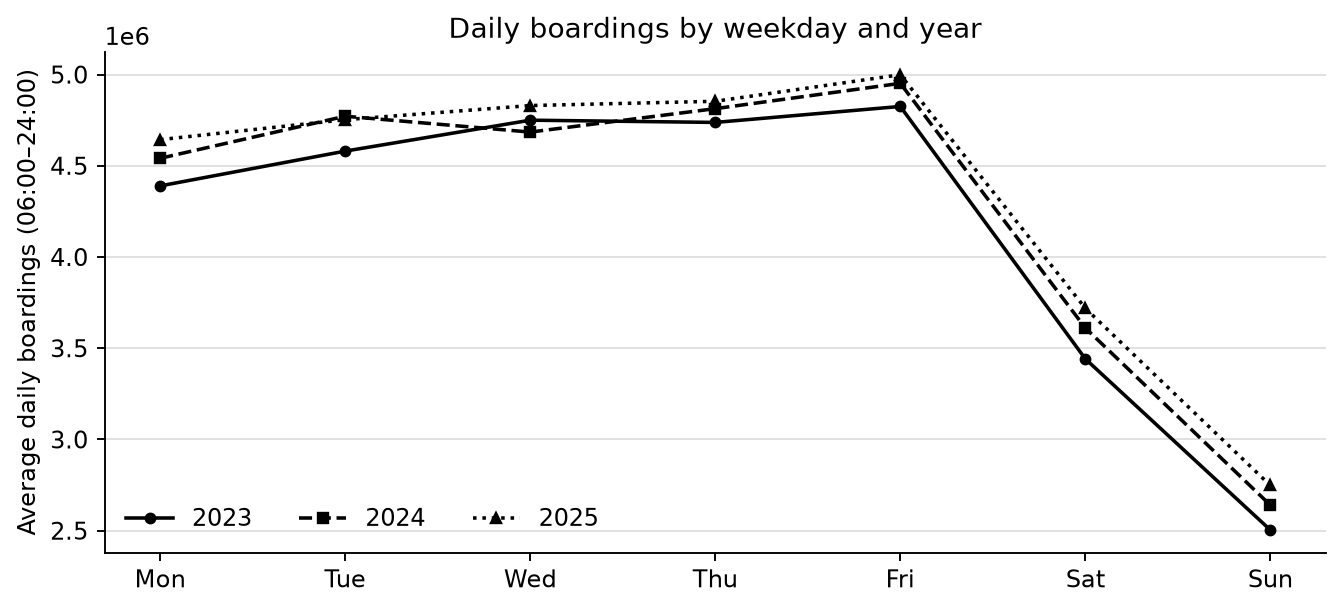

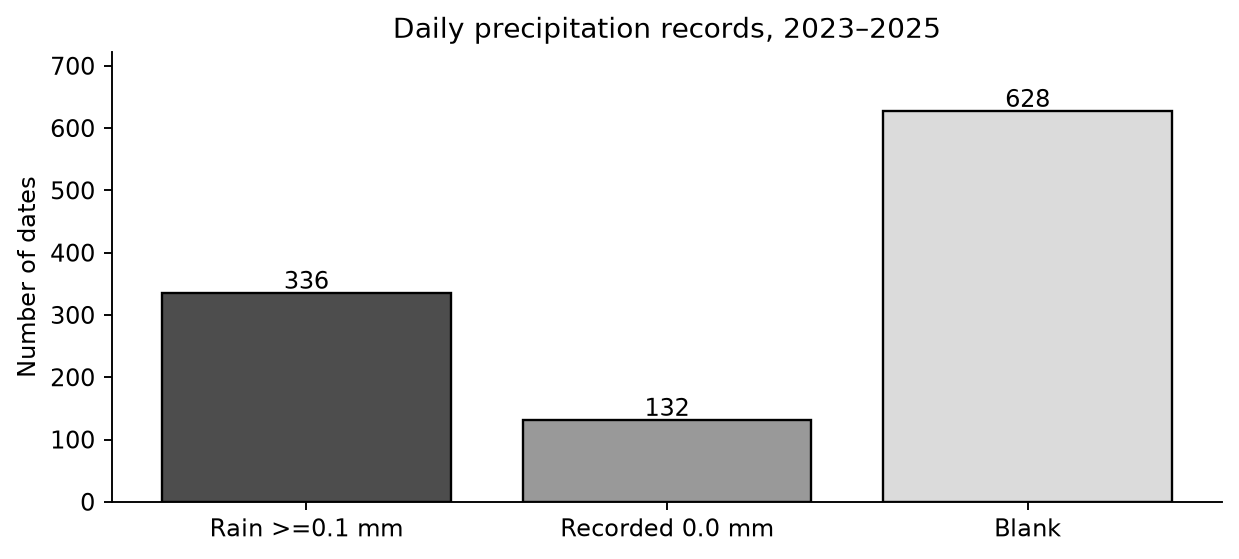

In [6]:
display(Image(filename='results/interim/figures/01_weekday_boardings.png'))
display(Image(filename='results/interim/figures/02_precipitation_records.png'))


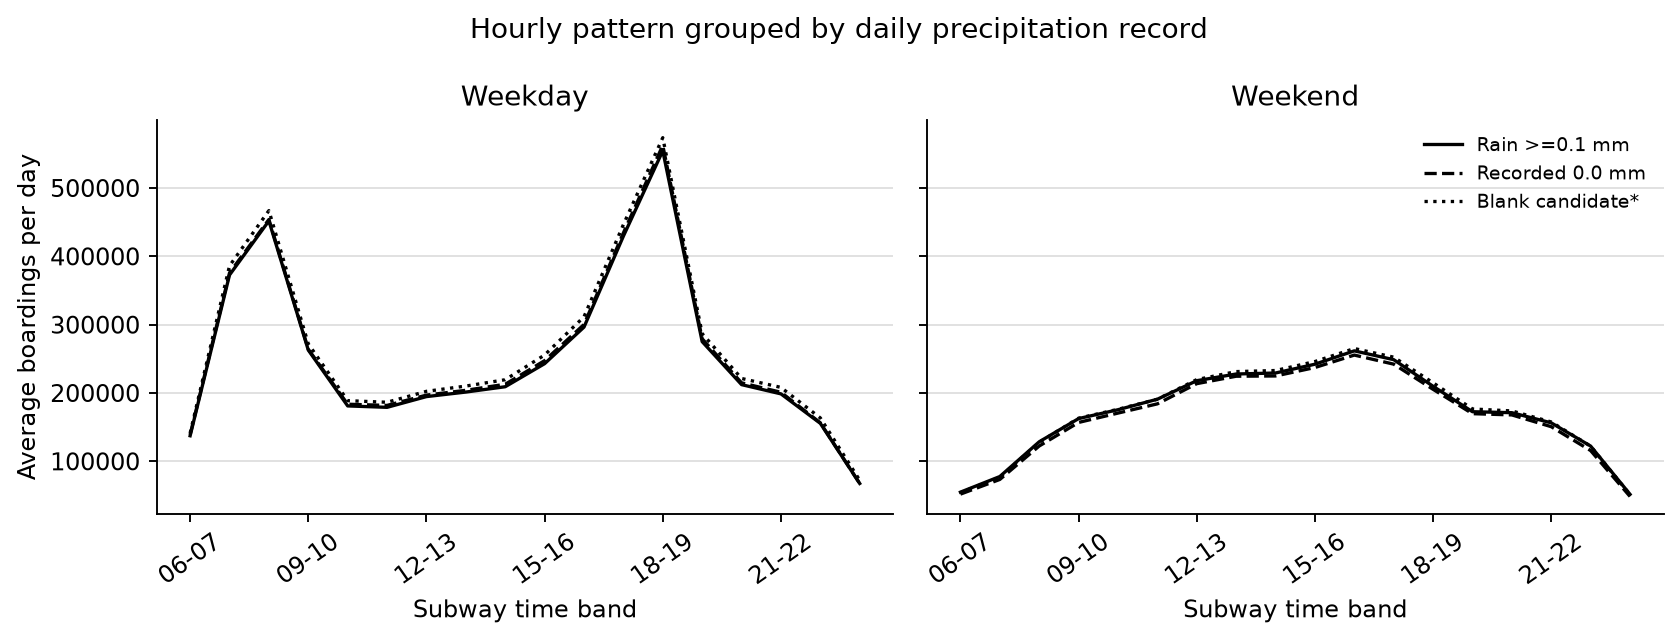

In [7]:
display(Image(filename='results/interim/figures/03_hourly_by_daily_precipitation.png'))


## 5. 중간 해석과 한계

- 일강수량은 특정 시간대에 비가 왔다는 뜻이 아니다. 눈 등도 강수량에 포함된다.
- 기상관측소 한 지점이 모든 역 주변의 날씨를 대표하지 못할 수 있다.
- 빈칸 후보는 무강수 확정값이 아니며, 공휴일·행사·운행 변화가 단순 비교에 영향을 줄 수 있다.
- 원자료 출처, AI 활용과 검증 기록은 별첨 자료를 참고한다.
